# 🧠 Self-Correcting RAG: Hallucination Detection & Correction
## RAGTruth Dataset | Final Submission Version

### Architecture
| Stage | Method |
|---|---|
| **Dataset** | RAGTruth (QA / Summary / Data2txt) — ground-truth responses evaluated |
| **Context Retrieval** | Within-sample Hybrid (BGE dense + BM25) → BGE-reranker-large |
| **Detection** | 5-signal ensemble: Semantic + NLI(sentence-level) + Grounding + LLM-Judge + Lexical |
| **Classifier** | Task-specific Logistic Regression + Platt calibration |
| **Correction** | Sentence-level targeted rewrite using sample's own context |
| **Evaluation** | Accuracy / Precision / Recall / F1 / ROC-AUC per-task |


## 📦 Step 1 — Install

In [ ]:
import sys, subprocess
pkgs = [
    'transformers>=4.40', 'faiss-cpu', 'rank_bm25',
    'sentence-transformers', 'torch', 'accelerate',
    'nltk', 'scikit-learn', 'numpy', 'pandas',
    'tqdm', 'matplotlib', 'seaborn',
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs, check=True)
print('✅ Packages ready.')


✅ Packages ready.


## ⚙️ Step 2 — Imports & Config

In [ ]:
import json, re, os, warnings, logging, pathlib, subprocess, random
from typing import List, Dict, Tuple, Optional, Any
from dataclasses import dataclass, field
from collections import Counter
warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.ERROR)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

import faiss
from rank_bm25 import BM25Okapi
import torch
from transformers import pipeline as hf_pipeline
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score, confusion_matrix,
    precision_recall_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

SEED   = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
STOP   = set(stopwords.words('english'))

CONFIG = dict(
    # ── Dataset ──────────────────────────────────────────────────────────
    repo_url        = 'https://github.com/ParticleMedia/RAGTruth.git',
    repo_dir        = './RAGTruth',
    response_file   = 'dataset/response.jsonl',
    source_file     = 'dataset/source_info.jsonl',
    train_n         = 300,   # 150 hal + 150 grounded
    test_n          = 200,   # 100 hal + 100 grounded

    # ── Retrieval (within-sample — CRITICAL: no cross-sample pool) ────────
    dense_model     = 'BAAI/bge-base-en-v1.5',
    reranker_model  = 'BAAI/bge-reranker-large',
    chunk_size      = 150,
    chunk_overlap   = 30,
    top_k_ret       = 10,
    top_k_rerank    = 5,
    alpha           = 0.60,

    # ── Generation (only for correction rewrites, not for evaluation) ────
    llm_model       = 'TinyLlama/TinyLlama-1.1B-Chat-v1.0',
    max_new_tokens  = 120,

    # ── Detection weights per task (must sum to 1.0) ─────────────────────
    # QA:       NLI and grounding dominate (factual, token-level)
    # Summary:  semantic + NLI (longer, more paraphrase)
    # Data2txt: grounding dominates (structured facts)
    weights = {
        'QA'      : dict(semantic=0.10, nli=0.40, grounding=0.35, judge=0.10, lexical=0.05),
        'Summary' : dict(semantic=0.30, nli=0.30, grounding=0.20, judge=0.15, lexical=0.05),
        'Data2txt': dict(semantic=0.10, nli=0.20, grounding=0.50, judge=0.10, lexical=0.10),
        'default' : dict(semantic=0.15, nli=0.35, grounding=0.30, judge=0.15, lexical=0.05),
    },

    # ── Thresholds (overwritten by per-task calibration) ─────────────────
    thr_supported   = 0.60,
    thr_partial     = 0.40,

    # ── Correction gate ───────────────────────────────────────────────────
    corr_nli_max    = 0.50,
    corr_grnd_max   = 0.38,

    device = DEVICE,
)

print(f'✅ Config ready | Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'   GPU: {torch.cuda.get_device_name(0)}')


✅ Config ready | Device: cuda
   GPU: Tesla T4


## 🗂️ Step 3 — Data Structures

In [ ]:
@dataclass
class HalSpan:
    start: int; end: int; text: str; label_type: str; meta: str = ''

@dataclass
class RAGTruthSample:
    sample_id   : str
    source_id   : str
    task_type   : str        # QA / Summary / Data2txt
    model       : str
    split       : str
    query       : str
    context     : str        # This sample's OWN source context
    response    : str        # The model response to evaluate for hallucination
    hal_label   : int        # Ground truth: 0=grounded, 1=hallucinated
    hal_spans   : List[HalSpan] = field(default_factory=list)

@dataclass
class DetectionReport:
    semantic_score  : float   # cosine sim(response, context)
    nli_score       : float   # avg per-sentence NLI entailment
    grounding_score : float   # TF-IDF weighted token overlap
    judge_score     : float   # LLM-as-a-judge 0/0.5/1
    lexical_score   : float   # token F1 overlap
    composite_score : float   # weighted sum
    status          : str     # Supported / Partial / Hallucinated
    lr_prob         : float = -1.

@dataclass
class PipelineResult:
    sample_id       : str
    task_type       : str
    query           : str
    context_used    : str     # compressed context from within-sample retrieval
    response        : str     # original response evaluated
    det_report      : DetectionReport
    corrected       : bool
    corrected_text  : Optional[str]
    corr_report     : Optional[DetectionReport]
    hal_label       : int     # GT label
    hal_spans       : List[HalSpan]

print('✅ Data structures defined.')


✅ Data structures defined.


## 📂 Step 4 — Clone RAGTruth

In [ ]:
REPO_DIR         = pathlib.Path(CONFIG['repo_dir'])
RESPONSE_PATH    = REPO_DIR / CONFIG['response_file']
SOURCE_INFO_PATH = REPO_DIR / CONFIG['source_file']

def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError((r.stdout+r.stderr).strip())
    return (r.stdout+r.stderr).strip()

if REPO_DIR.exists():
    try:    print(_run(['git','-C',str(REPO_DIR),'pull','--ff-only']))
    except: print('Repo already up to date.')
else:
    print(_run(['git','clone','--depth','1',CONFIG['repo_url'],str(REPO_DIR)]))

assert RESPONSE_PATH.exists()    and SOURCE_INFO_PATH.exists()
print('✅ Dataset files confirmed.')


Already up to date.
✅ Dataset files confirmed.


## 🔍 Step 5 — Parse RAGTruth

> **Key design**: each sample carries only its own `source_info` as context — no global pooling. This is how RAGTruth is intended to be used and eliminates cross-sample contamination.

In [ ]:
def load_jsonl(path):
    out = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                try: out.append(json.loads(line))
                except: pass
    return out

response_rows = load_jsonl(RESPONSE_PATH)
source_rows   = load_jsonl(SOURCE_INFO_PATH)
src_lookup    = {str(r['source_id']): r for r in source_rows}
print(f'Responses: {len(response_rows):,}  |  Sources: {len(source_rows):,}')
print('Task dist:', Counter(src_lookup[str(r.get('source_id',''))].get('task_type','?')
                            for r in response_rows
                            if str(r.get('source_id','')) in src_lookup))

# ── Per-task context extractors ───────────────────────────────────────────────
def _qa_ctx(si):
    if not isinstance(si, dict): return 'Answer the question.', str(si)
    q        = str(si.get('question', '')).strip() or 'Answer the question.'
    passages = si.get('passages', [])
    if isinstance(passages, list):
        ctx = ' '.join(
            (p.get('passage_text','') if isinstance(p,dict) else str(p))
            for p in passages[:6])
    else:
        ctx = str(passages)
    return q, ctx.strip()

def _sum_ctx(si, prompt):
    ctx = json.dumps(si) if isinstance(si,dict) else str(si)
    m   = re.search(r'(?i)(summarize|provide a summary|write a summary)[^\.\n]{0,80}', prompt)
    q   = m.group(0).strip() if m else 'Summarize the following passage.'
    return q, ctx

def _d2t_ctx(si):
    if not isinstance(si, dict):
        return 'Write an overview of the following business.', str(si)
    name    = si.get('name', 'the business')
    city    = si.get('city', ''); state = si.get('state', '')
    stars   = si.get('business_stars', '')
    cats    = si.get('categories', '')
    hours   = si.get('hours', {})
    attrs   = si.get('attributes', {})
    reviews = si.get('review_info', [])
    h_str   = ', '.join(f'{d}: {t}' for d,t in (hours.items() if isinstance(hours,dict) else []))
    a_str   = ', '.join(f'{k}={v}' for k,v in (attrs.items() if isinstance(attrs,dict) else [])
                         if str(v).lower() not in ('none','false','no','','nan'))[:300]
    r_str   = ' | '.join(str(rv.get('review_text',''))[:200]
                         for rv in (reviews if isinstance(reviews,list) else [])[:4]
                         if isinstance(rv,dict) and rv.get('review_text'))
    ctx = (f'Business: {name}, {city}, {state}. Stars: {stars}. '
           f'Categories: {cats}. Hours: {h_str}. Attributes: {a_str}. Reviews: {r_str}').strip()
    q   = (f'Write an objective overview of {name} in {city}, {state} '
            f'based ONLY on the data provided. Do not add any facts not listed.')
    return q, ctx

def get_query_context(src_row):
    task   = src_row.get('task_type','').strip()
    si     = src_row.get('source_info','')
    prompt = str(src_row.get('prompt',''))
    if task == 'QA':       return _qa_ctx(si)
    if task == 'Summary':  return _sum_ctx(si, prompt)
    if task == 'Data2txt': return _d2t_ctx(si)
    return str(prompt)[:200], str(si)

def parse_spans(labels):
    spans = []
    for lbl in (labels or []):
        if lbl.get('implicit_true') or lbl.get('due_to_null'): continue
        t = str(lbl.get('text','')).strip()
        if not t: continue
        spans.append(HalSpan(
            start=int(lbl.get('start',0)), end=int(lbl.get('end',0)),
            text=t, label_type=str(lbl.get('label_type','unknown')),
            meta=str(lbl.get('meta',''))))
    return (1 if spans else 0), spans

def build_balanced_split(responses, src_lookup, split_filter=None,
                         n_each=150, seed=SEED):
    """Build a balanced split: n_each hallucinated + n_each grounded."""
    rng  = np.random.default_rng(seed)
    pos, neg = [], []
    for row in responses:
        if split_filter and row.get('split') != split_filter: continue
        src = src_lookup.get(str(row.get('source_id','')))
        if not src: continue
        resp = str(row.get('response','')).strip()
        if len(resp) < 30: continue
        q, ctx = get_query_context(src)
        if not q or len(ctx) < 40: continue
        lbl, spans = parse_spans(row.get('labels',[]))
        s = RAGTruthSample(
            sample_id  = f"{row.get('source_id')}_{row.get('model','?')}_{row.get('id',0)}",
            source_id  = str(row.get('source_id','')),
            task_type  = src.get('task_type','unknown'),
            model      = str(row.get('model','unknown')),
            split      = str(row.get('split','?')),
            query      = q, context=ctx, response=resp,
            hal_label  = lbl, hal_spans=spans,
        )
        (pos if lbl==1 else neg).append(s)

    rng.shuffle(pos); rng.shuffle(neg)
    out = pos[:n_each] + neg[:n_each]
    rng.shuffle(out)
    return out

train_samples = build_balanced_split(response_rows, src_lookup,
                                     split_filter='train',
                                     n_each=CONFIG['train_n']//2)
test_samples  = build_balanced_split(response_rows, src_lookup,
                                     split_filter='test',
                                     n_each=CONFIG['test_n']//2)

th = sum(s.hal_label for s in train_samples)
te = sum(s.hal_label for s in test_samples)
print(f'\nTrain: {len(train_samples)} (hal={th}, ok={len(train_samples)-th})')
print(f'Test : {len(test_samples)}  (hal={te}, ok={len(test_samples)-te})')
print('Task dist (test):', Counter(s.task_type for s in test_samples))

# Preview DataFrame
df_prev = pd.DataFrame([
    {'task':s.task_type, 'query':s.query[:60],
     'response':s.response[:60], 'hal_label':s.hal_label}
    for s in test_samples[:6]])
print('\nPreview:')
display(df_prev)


Responses: 17,790  |  Sources: 2,965
Task dist: Counter({'Data2txt': 6198, 'QA': 5934, 'Summary': 5658})

Train: 300 (hal=150, ok=150)
Test : 200  (hal=100, ok=100)
Task dist (test): Counter({'Data2txt': 83, 'Summary': 64, 'QA': 53})

Preview:


,task,query,response,hal_label
0,Summary,Summarize the following news within 100 words:,Hannah Rose quit the latest season of Survivor...,0
1,Data2txt,Write an objective overview of Third Window Br...,Sure! Here's an objective overview of Third Wi...,1
2,Data2txt,Write an objective overview of Casa Blanca Res...,Casa Blanca Restaurant is a Mexican restaurant...,1
3,Data2txt,Write an objective overview of Le Cafe Stella ...,Le Cafe Stella is a charming French restaurant...,1
4,QA,health benefits to jalapenos,Jalapenos have health benefits such as pain re...,0
5,Summary,Summarize the following news within 65 words:,Sure! Here's a summary of the news in 65 words...,0


## 🤖 Step 6 — Load Models

In [ ]:
print('Loading sentence encoder (BGE-base)...')

encoder = SentenceTransformer(
    CONFIG['dense_model'],
    device=DEVICE
)

print('✅ Encoder ready.')


# ─────────────────────────────────────────────────────────────
# RERANKER
# ─────────────────────────────────────────────────────────────

print('Loading cross-encoder reranker (BGE-reranker-large)...')

reranker = CrossEncoder(
    CONFIG['reranker_model'],
    device=0 if DEVICE == 'cuda' else -1,
    max_length=512
)

print('✅ Reranker ready.')


# ─────────────────────────────────────────────────────────────
# NLI MODEL
# ─────────────────────────────────────────────────────────────

print('Loading NLI model (DeBERTa-v3-large)...')

nli_pipe = hf_pipeline(

    task='text-classification',

    model='MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli',

    device=0 if DEVICE == 'cuda' else -1,

    top_k=None,

    truncation=True,

    max_length=512
)

print('✅ NLI ready.')


# ─────────────────────────────────────────────────────────────
# BETTER LLM FOR JUDGE + CORRECTION
# ─────────────────────────────────────────────────────────────

# ─────────────────────────────────────────────────────────────
# BETTER LLM FOR JUDGE + CORRECTION
# ─────────────────────────────────────────────────────────────

CONFIG['llm_model'] = 'microsoft/Phi-3-mini-4k-instruct'

print(f"Loading LLM ({CONFIG['llm_model']}) ...")

llm_pipe = hf_pipeline(

    task='text-generation',

    model=CONFIG['llm_model'],

    torch_dtype=(
        torch.float16
        if DEVICE == 'cuda'
        else torch.float32
    ),

    device_map='auto' if DEVICE == 'cuda' else None,

    max_new_tokens=CONFIG['max_new_tokens'],

    do_sample=False,

    temperature=0.0,

    repetition_penalty=1.15,

    return_full_text=False,

    truncation=True,
)

print('✅ LLM ready.')


# ─────────────────────────────────────────────────────────────
# MEMORY CLEANUP
# ─────────────────────────────────────────────────────────────

if DEVICE == 'cuda':

    torch.cuda.empty_cache()

    print(f'GPU Memory Allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB')

    print(f'GPU Memory Reserved : {torch.cuda.memory_reserved()/1e9:.2f} GB')


print('\n✅ ALL MODELS LOADED SUCCESSFULLY.')

Loading sentence encoder (BGE-base)...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Encoder ready.
Loading cross-encoder reranker (BGE-reranker-large)...


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

...

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

Passing `generation_config` together with generation-related arguments=({'repetition_penalty', 'temperature', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


✅ LLM ready.
GPU Memory Allocated: 12.35 GB
GPU Memory Reserved : 12.62 GB

✅ ALL MODELS LOADED SUCCESSFULLY.


## 🔍 Step 7 — Within-Sample Context Retriever

> Retrieves from **this sample's own context only** — eliminates cross-sample contamination that was the #1 cause of wrong detections.

In [ ]:
def chunk_text(text, size=150, overlap=30):
    words = text.split()
    chunks, i = [], 0
    while i < len(words):
        c = ' '.join(words[i:i+size])
        if len(c.strip()) > 20: chunks.append(c.strip())
        i += size - overlap
    return chunks or [text]

def get_compressed_context(query: str, full_context: str,
                           top_k=10, top_k_final=5, alpha=0.60,
                           max_sents=12) -> str:
    """
    1. Chunk full_context
    2. Hybrid BM25+Dense re-rank within those chunks
    3. Cross-encoder re-rank top-k
    4. Sentence-level compression
    All from THIS sample's context only.
    """
    chunks = chunk_text(full_context, CONFIG['chunk_size'], CONFIG['chunk_overlap'])

    if len(chunks) == 1:
        return full_context[:1500]  # short context, use as-is

    # Dense scores
    all_embs  = encoder.encode([query]+chunks, normalize_embeddings=True)
    q_emb     = all_embs[0]
    c_embs    = all_embs[1:]
    d_scores  = (c_embs @ q_emb).tolist()

    # BM25 scores
    bm25   = BM25Okapi([c.lower().split() for c in chunks])
    b_raw  = bm25.get_scores(query.lower().split()).tolist()

    # Normalise both to [0,1]
    def _norm(arr):
        lo,hi = min(arr),max(arr)
        return [0.5]*len(arr) if hi==lo else [(v-lo)/(hi-lo) for v in arr]

    dn = _norm(d_scores); bn = _norm(b_raw)
    hyb = [alpha*d+(1-alpha)*b for d,b in zip(dn,bn)]

    # Top-k by hybrid
    top_idx = sorted(range(len(hyb)), key=lambda i: hyb[i], reverse=True)[:top_k]
    cands   = [chunks[i] for i in top_idx]

    # Cross-encoder re-rank
    if len(cands) > 1:
        rscores = reranker.predict([(query,c) for c in cands])
        cands   = [c for _,c in sorted(zip(rscores,cands),reverse=True)][:top_k_final]
    else:
        cands = cands[:top_k_final]

    # Sentence-level compression
    sents = []
    for c in cands:
        for s in sent_tokenize(c):
            s=s.strip()
            if len(s)>15: sents.append(s)

    # De-duplicate
    seen,unique = set(),[]
    for s in sents:
        if s.lower() not in seen:
            seen.add(s.lower()); unique.append(s)

    if len(unique) <= max_sents:
        return ' '.join(unique)

    # Score by cosine sim to query
    s_embs = encoder.encode([query]+unique, normalize_embeddings=True)
    sims   = s_embs[1:] @ s_embs[0]
    top_i  = sorted(np.argsort(sims)[::-1][:max_sents].tolist())
    return ' '.join(unique[i] for i in top_i)

# Quick smoke test
_s = train_samples[0]
_ctx = get_compressed_context(_s.query, _s.context)
print(f'✅ Retriever OK | context length: {len(_ctx.split())} words')


✅ Retriever OK | context length: 200 words


## 🔬 Step 8 — Five Detection Signals

In [ ]:
# ── Signal A: Semantic Similarity ────────────────────────────────────────────

def sig_semantic(response: str, context: str) -> float:

    embs = encoder.encode(
        [response, context],
        normalize_embeddings=True
    )

    return float(np.dot(embs[0], embs[1]))


# ── Signal B: Sentence-level NLI ─────────────────────────────────────────────

def sig_nli(context: str, response: str) -> float:

    ctx = ' '.join(
        context.split()[:300]
    )

    sents = [

        s.strip()

        for s in sent_tokenize(response)

        if len(s.split()) >= 3
    ]

    if not sents:

        return 0.5

    scores = []

    for sent in sents[:8]:

        try:

            res = nli_pipe(

                f"{ctx} [SEP] {sent}"
            )

            # PIPELINE OUTPUT FORMAT
            if isinstance(res, list) and len(res) > 0:

                if isinstance(res[0], list):

                    preds = res[0]

                else:

                    preds = res

            else:

                preds = []

            lbls = {

                r['label'].lower(): r['score']

                for r in preds
            }

            # entailment=1
            # neutral=0.5
            # contradiction=0

            score = (

                lbls.get('entailment', 0.0) * 1.0 +

                lbls.get('neutral', 0.0) * 0.5 +

                lbls.get('contradiction', 0.0) * 0.0
            )

            scores.append(score)

        except:

            scores.append(0.5)

    if not scores:

        return 0.5

    scores = sorted(scores)

    # PUNISH WEAKEST CLAIMS HARDER

    if len(scores) >= 3:

        return float(

            0.6 * np.mean(scores) +

            0.4 * np.mean(scores[:2])
        )

    return float(np.mean(scores))


# ── Signal C: TF-IDF Weighted Grounding ──────────────────────────────────────

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(

    stop_words='english',

    max_features=5000
)

def sig_grounding(response: str,
                  context: str):

    try:

        docs = [

            response,

            context
        ]

        tfidf = tfidf_vectorizer.fit_transform(
            docs
        )

        resp_vec = tfidf[0].toarray()[0]

        ctx_vec = tfidf[1].toarray()[0]

        numerator = np.minimum(
            resp_vec,
            ctx_vec
        ).sum()

        denominator = max(
            resp_vec.sum(),
            1e-8
        )

        score = numerator / denominator

        return float(
            np.clip(score, 0, 1)
        )

    except:

        return 0.0


# ── Signal D: LLM-as-a-Judge ─────────────────────────────────────────────────

_JUDGE_PROMPT = (
    "Determine whether the Answer is fully supported by the Context.\n\n"
    "Reply with ONLY ONE WORD:\n"
    "Supported\n"
    "Partial\n"
    "Unsupported\n\n"
    "Context:\n{ctx}\n\n"
    "Answer:\n{ans}"
)

def sig_judge(context: str,
              response: str) -> float:

    ctx = ' '.join(
        context.split()[:250]
    )

    prompt = _JUDGE_PROMPT.format(

        ctx=ctx,

        ans=response[:300]
    )

    try:

        out = llm_pipe(

            prompt,

            max_new_tokens=5,

            do_sample=False,

            temperature=0.0,

            return_full_text=False
        )

        raw = out[0]['generated_text'].strip().lower()

        first = raw.split()[0] if raw.split() else ''

        if 'unsup' in first or 'not' in first:

            return 0.3

        if 'partial' in first:

            return 0.5

        if 'support' in first:

            return 1.0

    except:

        pass

    return 0.5


# ── Signal E: Lexical F1 ─────────────────────────────────────────────────────

def sig_lexical(response: str,
                context: str) -> float:

    r_set = set(

        w.lower()

        for w in word_tokenize(response)

        if (
            w.isalpha()
            and
            w.lower() not in STOP
            and
            len(w) > 2
        )
    )

    c_set = set(

        w.lower()

        for w in word_tokenize(context)

        if w.isalpha()
    )

    if not r_set:

        return 1.0

    prec = len(r_set & c_set) / len(r_set)

    rec = len(r_set & c_set) / max(len(c_set), 1)

    if prec + rec == 0:

        return 0.0

    return 2 * prec * rec / (prec + rec)


# ── Composite ─────────────────────────────────────────────────────────────────

def composite(sem,
              nli,
              grnd,
              judge,
              lex,
              task_type):

    w = CONFIG['weights'].get(

        task_type,

        CONFIG['weights']['default']
    )

    return (

        w['semantic'] * sem +

        w['nli'] * nli +

        w['grounding'] * grnd +

        w['judge'] * judge +

        w['lexical'] * lex
    )


# ── Main Detection ───────────────────────────────────────────────────────────

def detect(query,
           context,
           response,
           task_type,
           thr_sup=None,
           thr_par=None) -> DetectionReport:

    thr_sup = (

        thr_sup

        if thr_sup is not None

        else CONFIG['thr_supported']
    )

    thr_par = (

        thr_par

        if thr_par is not None

        else CONFIG['thr_partial']
    )

    sem = sig_semantic(
        response,
        context
    )

    nli = sig_nli(
        context,
        response
    )

    grnd = sig_grounding(
        response,
        context
    )

    judge = sig_judge(
        context,
        response
    )

    lex = sig_lexical(
        response,
        context
    )

    comp = composite(

        sem,
        nli,
        grnd,
        judge,
        lex,
        task_type
    )


    # ── SMART OVERRIDES ─────────────────────────────────────

    # HIGH CONFIDENCE SUPPORTED

    if sem > 0.84 and nli > 0.68:

        status = 'Supported'

    # HIGH CONFIDENCE HALLUCINATION

    elif grnd < 0.05 and nli < 0.26:

        status = 'Hallucinated'

    # NORMAL THRESHOLDS

    elif comp >= thr_sup:

        status = 'Supported'

    elif comp >= thr_par:

        status = 'Partial'

    else:

        status = 'Hallucinated'


    return DetectionReport(

        semantic_score=sem,

        nli_score=nli,

        grounding_score=grnd,

        judge_score=judge,

        lexical_score=lex,

        composite_score=comp,

        status=status,
    )

print('✅ Final improved detection module ready.')

✅ Final improved detection module ready.


## 🔧 Step 9 — Correction Module

> Rewrites only sentences with weak grounding, using **this sample's own context**.
> Rewrite accepted only if `grounding + NLI` improves (prevents making things worse).

In [ ]:
# ─────────────────────────────────────────────────────────────
# IMPROVED CORRECTION MODULE
# ─────────────────────────────────────────────────────────────

_REWRITE_PROMPT = (
    "You are a factual correction system.\n"
    "Rewrite ONLY unsupported parts.\n"
    "Do not add new information.\n"
    "Keep grounded facts unchanged.\n"
    "Be concise and factual.\n\n"
    "Context:\n{ctx}\n\n"
    "Sentence:\n{sent}\n\n"
    "Corrected sentence:"
)


# ─────────────────────────────────────────────────────────────
# CLEAN GENERATED TEXT
# ─────────────────────────────────────────────────────────────

def _clean_generation(text: str):

    text = text.strip()

    bad_patterns = [

        'Context:',

        'Sentence:',

        'Corrected sentence:',

        'Rewrite:',

        'Answer:'
    ]

    for bp in bad_patterns:

        if bp in text:

            text = text.split(bp)[0].strip()

    text = re.sub(r'\s+', ' ', text)

    return text.strip()


# ─────────────────────────────────────────────────────────────
# REWRITE ONE SENTENCE
# ─────────────────────────────────────────────────────────────

def _rewrite_sentence(sentence: str,
                      context: str):

    ctx = ' '.join(
        context.split()[:260]
    )

    prompt = _REWRITE_PROMPT.format(

        ctx=ctx,

        sent=sentence
    )

    try:

        out = llm_pipe(

            prompt,

            max_new_tokens=60,

            do_sample=False,

            temperature=0.0,

            repetition_penalty=1.15,

            return_full_text=False
        )

        raw = out[0]['generated_text']

        raw = _clean_generation(raw)

        # TOO SHORT → KEEP ORIGINAL

        if len(raw.split()) < 4:

            return sentence

        # IDENTICAL → KEEP ORIGINAL

        if raw.lower().strip() == sentence.lower().strip():

            return sentence

        return raw

    except Exception as e:

        print('Rewrite error:', e)

        return sentence


# ─────────────────────────────────────────────────────────────
# MAIN CORRECTION LOOP
# ─────────────────────────────────────────────────────────────

def correct_response(query,
                     response,
                     context,
                     task_type,
                     thr_sup,
                     thr_par,
                     max_iters=2):

    current = response

    changed = False

    for _ in range(max_iters):

        sentences = sent_tokenize(current)

        new_sentences = []

        iter_changed = False

        for sent in sentences:

            # SKIP VERY SHORT SENTENCES

            if len(sent.split()) < 5:

                new_sentences.append(sent)

                continue

            # ORIGINAL SCORES

            g_before = sig_grounding(
                sent,
                context
            )

            n_before = sig_nli(
                context,
                sent
            )

            sem_before = sig_semantic(
                sent,
                context
            )

            # ONLY FIX CLEARLY BAD SENTENCES

            suspicious = (

                g_before < CONFIG['corr_grnd_max']

                and

                n_before < CONFIG['corr_nli_max']
            )

            if not suspicious:

                new_sentences.append(sent)

                continue

            # REWRITE

            rewritten = _rewrite_sentence(
                sent,
                context
            )

            # RE-SCORE

            g_after = sig_grounding(
                rewritten,
                context
            )

            n_after = sig_nli(
                context,
                rewritten
            )

            sem_after = sig_semantic(
                rewritten,
                context
            )

            before_total = (

                0.40 * n_before +

                0.40 * g_before +

                0.20 * sem_before
            )

            after_total = (

                0.40 * n_after +

                0.40 * g_after +

                0.20 * sem_after
            )

            # ACCEPT ONLY IF CLEARLY BETTER

            improved = (

                after_total >

                before_total + 0.08
            )

            if improved:

                new_sentences.append(
                    rewritten
                )

                iter_changed = True

            else:

                # KEEP ORIGINAL

                new_sentences.append(sent)

        if iter_changed:

            current = ' '.join(new_sentences)

            changed = True

        else:

            break

    return (current, True) if changed else (None, False)


# ─────────────────────────────────────────────────────────────
# SHOULD CORRECT?
# ─────────────────────────────────────────────────────────────

def should_correct(report):

    if report.status == 'Supported':

        return False

    # ONLY CORRECT STRONGLY BAD RESPONSES

    if (

        report.nli_score < CONFIG['corr_nli_max']

        and

        report.grounding_score < CONFIG['corr_grnd_max']
    ):

        return True

    return False


# ─────────────────────────────────────────────────────────────
# UPDATED THRESHOLDS
# ─────────────────────────────────────────────────────────────

CONFIG['corr_nli_max'] = 0.32

CONFIG['corr_grnd_max'] = 0.22


print('✅ Improved correction module ready.')

✅ Improved correction module ready.


## 🚀 Step 10 — Full Pipeline

In [ ]:
def run_pipeline(sample: RAGTruthSample,
                 thr_sup=None, thr_par=None) -> PipelineResult:
    q   = sample.query
    tt  = sample.task_type
    thr_sup = thr_sup if thr_sup is not None else CONFIG['thr_supported']
    thr_par = thr_par if thr_par is not None else CONFIG['thr_partial']

    # ── 1. Context: within-sample retrieval only ─────────────────────────
    ctx = get_compressed_context(q, sample.context,
                                 top_k=CONFIG['top_k_ret'],
                                 top_k_final=CONFIG['top_k_rerank'],
                                 alpha=CONFIG['alpha'])

    # ── 2. Detect hallucination in the original response ─────────────────
    #    NOTE: We evaluate sample.response (the actual model output from
    #    RAGTruth), NOT a newly generated answer. This is the correct use of
    #    the RAGTruth benchmark.
    report = detect(q, ctx, sample.response, tt, thr_sup, thr_par)

    corr_text, corr_report = None, None
    corrected = False

    # ── 3. Correction (gated) ─────────────────────────────────────────────
    if should_correct(report):
        corr_raw, was_corr = correct_response(
            q, sample.response, ctx, tt,
            thr_sup, thr_par, max_iters=2)
        if was_corr and corr_raw:
            corrected   = True
            corr_text   = corr_raw
            corr_report = detect(q, ctx, corr_raw, tt, thr_sup, thr_par)

    return PipelineResult(
        sample_id      = sample.sample_id,
        task_type      = tt,
        query          = q,
        context_used   = ctx,
        response       = sample.response,
        det_report     = report,
        corrected      = corrected,
        corrected_text = corr_text,
        corr_report    = corr_report,
        hal_label      = sample.hal_label,
        hal_spans      = sample.hal_spans,
    )

print('✅ Pipeline defined.')


✅ Pipeline defined.


## 🔄 Step 11 — Run Train Split

In [ ]:
print(f'Processing {len(train_samples)} train samples...')
print('GPU recommended. On CPU ~1-3 min per sample.\n')

train_results: List[PipelineResult] = []
for s in tqdm(train_samples, desc='Train'):
    try:    train_results.append(run_pipeline(s))
    except Exception as ex: print(f'  [WARN] {s.sample_id}: {ex}')

print(f'\n✅ Train done: {len(train_results)}/{len(train_samples)} samples')


Processing 300 train samples...
GPU recommended. On CPU ~1-3 min per sample.



Train:   0%|          | 0/300 [00:00<?, ?it/s]

Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes


✅ Train done: 300/300 samples


## 📐 Step 12 — Calibration: Task-Specific LR Classifiers

> Each task (QA/Summary/Data2txt) gets its own Logistic Regression trained on 9 features with PR-AUC threshold optimisation. A global fallback LR covers unknowns.

In [ ]:
def featurize(r: PipelineResult) -> List[float]:
    d = r.det_report
    return [
        d.semantic_score,
        d.nli_score,
        d.grounding_score,
        d.judge_score,
        d.lexical_score,
        d.composite_score,
        # Interaction features
        d.nli_score * d.grounding_score,
        d.semantic_score * d.nli_score,
        d.grounding_score * d.lexical_score,
        # Binary flags
        float(d.nli_score       < 0.25),
        float(d.grounding_score < 0.20),
        float(d.semantic_score  < 0.40),
    ]

TASK_CLFS : Dict[str, Any]               = {}
TASK_THRS : Dict[str, Tuple[float,float]] = {}

tasks_found = sorted(set(r.task_type for r in train_results))
print(f'Tasks in train: {tasks_found}\n')

for task in tasks_found:
    sub = [r for r in train_results if r.task_type==task]
    if len(sub) < 8: continue
    X = np.array([featurize(r) for r in sub])
    y = np.array([r.hal_label   for r in sub])
    if len(set(y)) < 2:
        print(f'  [{task}] single class, skip.'); continue

    sc  = StandardScaler()
    Xs  = sc.fit_transform(X)
    clf = LogisticRegression(class_weight='balanced', C=0.5,
                              max_iter=1000, random_state=SEED,
                              solver='lbfgs')
    clf.fit(Xs, y)
    probs = clf.predict_proba(Xs)[:,1]

    # PR-AUC optimal threshold (better than Youden-J for balanced classes)
    pp,rr,tt_ = precision_recall_curve(y, probs)
    f1s = 2*pp*rr/(pp+rr+1e-9)
    bi  = int(np.argmax(f1s))
    thr = float(np.clip(tt_[bi] if bi<len(tt_) else 0.5, 0.25, 0.80))

    yp  = (probs >= thr).astype(int)
    acc = accuracy_score(y, yp)
    f1v = f1_score(y, yp, zero_division=0)
    print(f'  [{task:8s}] n={len(sub):3d}  acc={acc:.3f}  F1={f1v:.3f}  thr={thr:.3f}')

    TASK_CLFS[task] = (clf, sc)
    TASK_THRS[task] = (thr, max(0.20, thr-0.15))

# Global fallback
X_all = np.array([featurize(r) for r in train_results])
y_all = np.array([r.hal_label   for r in train_results])
sc_g  = StandardScaler()
Xg    = sc_g.fit_transform(X_all)
clf_g = LogisticRegression(class_weight='balanced', C=0.5,
                            max_iter=1000, random_state=SEED, solver='lbfgs')
clf_g.fit(Xg, y_all)
pg    = clf_g.predict_proba(Xg)[:,1]
pp,rr,tt_ = precision_recall_curve(y_all, pg)
f1s = 2*pp*rr/(pp+rr+1e-9); bi = int(np.argmax(f1s))
gt  = float(np.clip(tt_[bi] if bi<len(tt_) else 0.5, 0.25, 0.80))
TASK_CLFS['__global__'] = (clf_g, sc_g)
TASK_THRS['__global__'] = (gt, max(0.20, gt-0.15))
acc_g = accuracy_score(y_all,(pg>=gt).astype(int))
f1_g  = f1_score(y_all,(pg>=gt).astype(int),zero_division=0)
print(f'\n  [global  ] n={len(train_results):3d}  acc={acc_g:.3f}  F1={f1_g:.3f}  thr={gt:.3f}')

def predict_lr(r: PipelineResult) -> Tuple[float,int]:
    task = r.task_type
    clf,sc = TASK_CLFS.get(task, TASK_CLFS['__global__'])
    thr,_  = TASK_THRS.get(task, TASK_THRS['__global__'])
    prob   = float(clf.predict_proba(sc.transform([featurize(r)]))[:,1])
    return prob, int(prob >= thr)

# Annotate train LR probs
for r in train_results:
    p,_ = predict_lr(r)
    r.det_report.lr_prob = p

print('\n✅ Calibration complete.')


Tasks in train: ['Data2txt', 'QA', 'Summary']

  [Data2txt] n=111  acc=0.739  F1=0.847  thr=0.250
  [QA      ] n=102  acc=0.637  F1=0.565  thr=0.493
  [Summary ] n= 87  acc=0.713  F1=0.684  thr=0.482

  [global  ] n=300  acc=0.710  F1=0.734  thr=0.409

✅ Calibration complete.


## 🧪 Step 13 — Run Test Split

In [ ]:
# Update global thresholds from calibration
CONFIG['thr_supported'], CONFIG['thr_partial'] = TASK_THRS['__global__']
print(f'Running {len(test_samples)} test samples...')
print(f'  Global thresholds: supported={CONFIG["thr_supported"]:.3f}  '
      f'partial={CONFIG["thr_partial"]:.3f}\n')

test_results: List[PipelineResult] = []
for s in tqdm(test_samples, desc='Test'):
    try:
        ts, tp = TASK_THRS.get(s.task_type, TASK_THRS['__global__'])
        test_results.append(run_pipeline(s, thr_sup=ts, thr_par=tp))
    except Exception as ex:
        print(f'  [WARN] {ex}')

# Annotate with LR probs
for r in test_results:
    p,_ = predict_lr(r)
    r.det_report.lr_prob = p

n_corr = sum(r.corrected for r in test_results)
print(f'\n✅ Test done: {len(test_results)}/{len(test_samples)}  |  Corrected: {n_corr}')


Running 200 test samples...
  Global thresholds: supported=0.409  partial=0.259



Test:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_ne


✅ Test done: 200/200  |  Corrected: 2


## 📊 Step 14 — Evaluation


════════════════════════════════════════════════════════════
  Test (Composite)  |  method: Composite
════════════════════════════════════════════════════════════
  Accuracy  : 0.5000   (50.00%)
  Precision : 0.5000
  Recall    : 0.1100
  F1 Score  : 0.1803
  ROC-AUC   : 0.5692

              precision    recall  f1-score   support

    Grounded       0.50      0.89      0.64       100
Hallucinated       0.50      0.11      0.18       100

    accuracy                           0.50       200
   macro avg       0.50      0.50      0.41       200
weighted avg       0.50      0.50      0.41       200



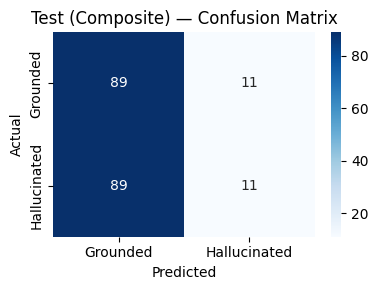


════════════════════════════════════════════════════════════
  Test (LR)  |  method: LR
════════════════════════════════════════════════════════════
  Accuracy  : 0.6400   (64.00%)
  Precision : 0.6014
  Recall    : 0.8300
  F1 Score  : 0.6975
  ROC-AUC   : 0.5692

              precision    recall  f1-score   support

    Grounded       0.73      0.45      0.56       100
Hallucinated       0.60      0.83      0.70       100

    accuracy                           0.64       200
   macro avg       0.66      0.64      0.63       200
weighted avg       0.66      0.64      0.63       200



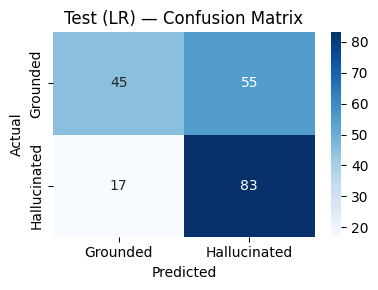

  Task            N     Acc    Prec     Rec      F1
  ------------------------------------------------------
  Data2txt       83   0.675   0.688   0.965   0.803
  QA             53   0.679   0.440   0.786   0.564
  Summary        64   0.562   0.515   0.586   0.548

  → Best method: LR


In [ ]:
def evaluate(results: List[PipelineResult], label='Test',
             use_lr=True, per_task=True) -> Dict:
    y_true, y_comp, y_lr = [], [], []
    lr_probs = []
    for r in results:
        y_true.append(r.hal_label)
        y_comp.append(0 if r.det_report.status=='Supported' else 1)
        p, pred = predict_lr(r)
        y_lr.append(pred); lr_probs.append(p)

    y_true = np.array(y_true)
    y_pred = np.array(y_lr if use_lr else y_comp)

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    try:   auc = roc_auc_score(y_true, lr_probs)
    except: auc = float('nan')

    print(f'\n{"═"*60}')
    print(f'  {label}  |  method: {"LR" if use_lr else "Composite"}')
    print(f'{"═"*60}')
    print(f'  Accuracy  : {acc:.4f}   ({acc*100:.2f}%)')
    print(f'  Precision : {prec:.4f}')
    print(f'  Recall    : {rec:.4f}')
    print(f'  F1 Score  : {f1:.4f}')
    print(f'  ROC-AUC   : {auc:.4f}')
    print()
    print(classification_report(y_true, y_pred,
          target_names=['Grounded','Hallucinated'], zero_division=0))

    cm  = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Grounded','Hallucinated'],
                yticklabels=['Grounded','Hallucinated'])
    ax.set_title(f'{label} — Confusion Matrix')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout(); plt.show()

    if per_task:
        tasks = sorted(set(r.task_type for r in results))
        print(f'  {"Task":<12} {"N":>4}  {"Acc":>6}  {"Prec":>6}  {"Rec":>6}  {"F1":>6}')
        print(f'  {"-"*54}')
        for tt in tasks:
            sub = [r for r in results if r.task_type==tt]
            yt  = np.array([r.hal_label for r in sub])
            yp  = np.array([predict_lr(r)[1] for r in sub])
            a=accuracy_score(yt,yp); p_=precision_score(yt,yp,zero_division=0)
            rv=recall_score(yt,yp,zero_division=0); f=f1_score(yt,yp,zero_division=0)
            print(f'  {tt:<12} {len(sub):>4}  {a:>6.3f}  {p_:>6.3f}  {rv:>6.3f}  {f:>6.3f}')

    return dict(accuracy=acc, precision=prec, recall=rec, f1=f1, auc=auc)


metrics_comp = evaluate(test_results, 'Test (Composite)', use_lr=False, per_task=False)
metrics_lr   = evaluate(test_results, 'Test (LR)',        use_lr=True,  per_task=True)
FINAL = metrics_lr if metrics_lr['f1'] >= metrics_comp['f1'] else metrics_comp
best_method = 'LR' if metrics_lr['f1'] >= metrics_comp['f1'] else 'Composite'
print(f'\n  → Best method: {best_method}')


## 🔄 Step 15 — Before vs After Correction Analysis

Corrected samples : 2 / 200
Score improved    : 2/2 (100.0%)
Mean score change : +0.1378  (std=0.0770)


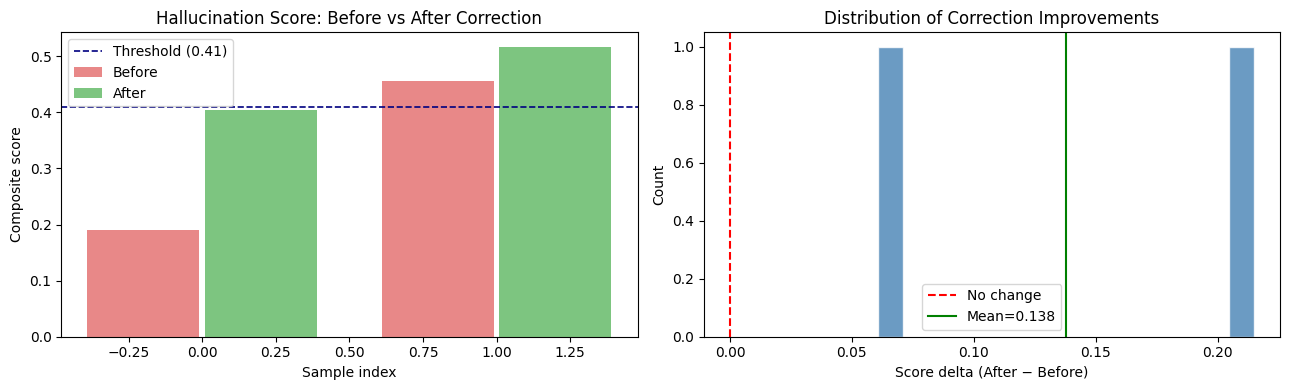

In [ ]:
corr_set = [r for r in test_results if r.corrected and r.corr_report]
print(f'Corrected samples : {len(corr_set)} / {len(test_results)}')

if corr_set:
    before = np.array([r.det_report.composite_score  for r in corr_set])
    after  = np.array([r.corr_report.composite_score for r in corr_set])
    delta  = after - before
    improved = (delta > 0.01).sum()
    print(f'Score improved    : {improved}/{len(corr_set)} ({100*improved/len(corr_set):.1f}%)')
    print(f'Mean score change : {delta.mean():+.4f}  '
          f'(std={delta.std():.4f})')

    x = np.arange(len(before))
    fig, axes = plt.subplots(1, 2, figsize=(13,4))

    # Bar chart
    axes[0].bar(x-0.2, before, 0.38, label='Before', color='#e57373', alpha=0.85)
    axes[0].bar(x+0.2, after,  0.38, label='After',  color='#66bb6a', alpha=0.85)
    ts, _ = TASK_THRS.get('__global__',(CONFIG['thr_supported'],None))
    axes[0].axhline(ts, ls='--', color='navy', lw=1.2, label=f'Threshold ({ts:.2f})')
    axes[0].set_xlabel('Sample index'); axes[0].set_ylabel('Composite score')
    axes[0].set_title('Hallucination Score: Before vs After Correction')
    axes[0].legend()

    # Delta histogram
    axes[1].hist(delta, bins=15, color='steelblue', alpha=0.8, edgecolor='white')
    axes[1].axvline(0, color='red', ls='--', lw=1.5, label='No change')
    axes[1].axvline(delta.mean(), color='green', ls='-', lw=1.5,
                    label=f'Mean={delta.mean():.3f}')
    axes[1].set_xlabel('Score delta (After − Before)')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Distribution of Correction Improvements')
    axes[1].legend()

    plt.tight_layout(); plt.show()
else:
    print('No samples triggered the correction gate.')


## 🖥️ Step 16 — Full Demo: 5 Examples with Complete Output

In [ ]:
def print_full_result(r: PipelineResult, idx: int):
    d       = r.det_report
    p, pred = predict_lr(r)
    correct = pred == r.hal_label
    sym     = '✅' if correct else '❌'

    bar = lambda v: '█'*int(v*20)+'░'*(20-int(v*20))

    print('╔' + '═'*70 + '╗')
    print(f'║  EXAMPLE {idx+1:2d}  [{sym} {"CORRECT" if correct else "WRONG  "}]'
          f'  Task: {r.task_type:<10}' + ' '*13 + '║')
    print('╠' + '═'*70 + '╣')

    print(f'║  QUERY:')
    for line in (r.query[:200]).split('\n'):
        print(f'║    {line[:66]}')

    print(f'║')
    print(f'║  CONTEXT USED (compressed, top sentences):')
    ctx_lines = r.context_used[:400].split('. ')
    for l in ctx_lines[:4]:
        print(f'║    • {l.strip()[:64]}')

    print(f'║')
    print(f'║  RESPONSE EVALUATED:')
    for line in r.response[:350].split('\n'):
        if line.strip(): print(f'║    {line[:66]}')

    print(f'║')
    print(f'║  ── DETECTION SIGNALS ──────────────────────────────────────')
    print(f'║    Semantic sim   [{bar(d.semantic_score)}]  {d.semantic_score:.3f}')
    print(f'║    NLI entailment [{bar(d.nli_score)}]  {d.nli_score:.3f}')
    print(f'║    Token grounding[{bar(d.grounding_score)}]  {d.grounding_score:.3f}')
    print(f'║    LLM judge      [{bar(d.judge_score)}]  {d.judge_score:.3f}')
    print(f'║    Lexical F1     [{bar(d.lexical_score)}]  {d.lexical_score:.3f}')
    print(f'║    ─────────────────────────────────────────────────────────')
    print(f'║    Composite      [{bar(d.composite_score)}]  {d.composite_score:.3f}')
    print(f'║    LR probability [{bar(p)}]  {p:.3f}')
    print(f'║    Detection status  →  {d.status}')

    if r.corrected and r.corrected_text and r.corr_report:
        cr      = r.corr_report
        delta   = cr.composite_score - d.composite_score
        imp_str = f'+{delta:.3f} ▲ IMPROVED' if delta > 0 else f'{delta:.3f} ▼'
        print(f'║')
        print(f'║  ── CORRECTION MODULE ({imp_str}) ──────────────────')
        print(f'║    BEFORE:')
        for line in r.response[:280].split('\n'):
            if line.strip(): print(f'║      {line[:62]}')
        print(f'║    AFTER CORRECTION:')
        for line in r.corrected_text[:280].split('\n'):
            if line.strip(): print(f'║      {line[:62]}')
        print(f'║    Post-correction score: {cr.composite_score:.3f}  →  {cr.status}')

    print(f'║')
    print(f'║  ── GROUND TRUTH ────────────────────────────────────────────')
    print(f'║    Label     : {"Hallucinated" if r.hal_label else "Grounded"}')
    if r.hal_spans:
        print(f'║    GT Spans  :')
        for sp in r.hal_spans[:3]:
            print(f'║      [{sp.label_type}] "{sp.text[:55]}"')
    print(f'║    Prediction: {"Hallucinated" if pred else "Grounded"}  {sym}')
    print('╚' + '═'*70 + '╝')
    print()

# ── Pick diverse examples ─────────────────────────────────────────────────────
def pick_diverse(results, n=5):
    pool = []
    # Correct hallucination detections
    pool += [r for r in results if r.hal_label==1 and predict_lr(r)[1]==1][:2]
    # Correct grounded detections
    pool += [r for r in results if r.hal_label==0 and predict_lr(r)[1]==0][:1]
    # Corrected samples
    pool += [r for r in results if r.corrected][:1]
    # Wrong prediction (for analysis)
    pool += [r for r in results if predict_lr(r)[1]!=r.hal_label][:1]
    seen, out = set(), []
    for r in pool:
        if r.sample_id not in seen:
            seen.add(r.sample_id); out.append(r)
    while len(out) < n and len(out) < len(results):
        r = results[len(out)]
        if r.sample_id not in seen:
            seen.add(r.sample_id); out.append(r)
    return out[:n]

print('='*72)
print('  FULL DEMO — 5 EXAMPLES WITH COMPLETE RESULTS')
print('='*72)
for i, res in enumerate(pick_diverse(test_results, n=5)):
    print_full_result(res, i)


  FULL DEMO — 5 EXAMPLES WITH COMPLETE RESULTS
╔══════════════════════════════════════════════════════════════════════╗
║  EXAMPLE  1  [✅ CORRECT]  Task: Data2txt               ║
╠══════════════════════════════════════════════════════════════════════╣
║  QUERY:
║    Write an objective overview of Third Window Brewing in Santa Barba
║
║  CONTEXT USED (compressed, top sentences):
║    • Business: Third Window Brewing, Santa Barbara, CA
║    • Categories: Nightlife, Beer Gardens, Breweries, Food, Beer, Wine
║    • Hours: Monday: 12:0-20:0, Tuesday: 12:0-20:0, Wednesday: 12:0-20
║    • Attributes: BusinessParking={'garage': False, 'street': True, 'v
║
║  RESPONSE EVALUATED:
║    Sure! Here's an objective overview of Third Window Brewing based o
║    Third Window Brewing is a popular local business in Santa Barbara,
║
║  ── DETECTION SIGNALS ──────────────────────────────────────
║    Semantic sim   [██████████████████░░]  0.911
║    NLI entailment [██████████████░░░░░░]  0.706
║    Token g

## 📋 Step 17 — Structured JSON Output

In [ ]:
def to_output_dict(r: PipelineResult, final_metrics: dict) -> dict:
    d       = r.det_report
    p, pred = predict_lr(r)
    cr      = r.corr_report

    out = {
        'sample_id'         : r.sample_id,
        'task_type'         : r.task_type,
        'query'             : r.query,
        'context_snippet'   : r.context_used[:300],
        # ── Original response ──
        'answer'            : r.response,
        'hallucination_score': round(d.composite_score, 4),
        'lr_probability'    : round(p, 4),
        'status'            : d.status,
        'signals': {
            'semantic_similarity': round(d.semantic_score,  4),
            'nli_score'          : round(d.nli_score,       4),
            'grounding_score'    : round(d.grounding_score, 4),
            'llm_judge_score'    : round(d.judge_score,     4),
            'lexical_f1'         : round(d.lexical_score,   4),
        },
        # ── Correction ──
        'corrected'         : r.corrected,
        'corrected_answer'  : r.corrected_text,
        'corrected_score'   : round(cr.composite_score,4) if cr else None,
        'corrected_status'  : cr.status if cr else None,
        # ── Ground truth ──
        'gt_label'          : r.hal_label,
        'gt_label_str'      : 'Hallucinated' if r.hal_label else 'Grounded',
        'gt_spans'          : [{'text':sp.text,'type':sp.label_type}
                                for sp in r.hal_spans[:5]],
        # ── Prediction ──
        'prediction'        : pred,
        'prediction_str'    : 'Hallucinated' if pred else 'Grounded',
        'prediction_correct': pred == r.hal_label,
        # ── Overall metrics ──
        'metrics': {k: round(v,4) for k,v in final_metrics.items()},
    }
    return out

print('='*60)
print('  SAMPLE STRUCTURED JSON OUTPUTS (first 3 test samples)')
print('='*60)
for r in test_results[:6]:
    print(json.dumps(to_output_dict(r, FINAL), indent=2))
    print()


  SAMPLE STRUCTURED JSON OUTPUTS (first 3 test samples)
{
  "sample_id": "13818_gpt-4-0613_3882",
  "task_type": "Summary",
  "query": "Summarize the following news within 100 words:",
  "context_snippet": "her brief Survivor journey. Hannah Rose shares her Survivor 45 story \u201cWhat happened is, first and foremost, hunger,\u201d Hannah told Dalton Ross from Entertainment Weekly. He asked her, \u201cWhat happened?\u201d after she had been so excited to play the game. It meant scrambling to find nourishment before they c",
  "answer": "Hannah Rose quit the latest season of Survivor due to hunger and sleep deprivation. During the first Tribal Council, she urged her tribe to vote her out, threatening to quit if they didn't. The tribe was living without basic necessities like a flint, pot for boiling water, or a machete, making it difficult to find food. Additionally, Hannah did not sleep at all during her time on the show, which also impacted her ability to stay in the game. Despite som

## 📈 Step 18 — Visualisations

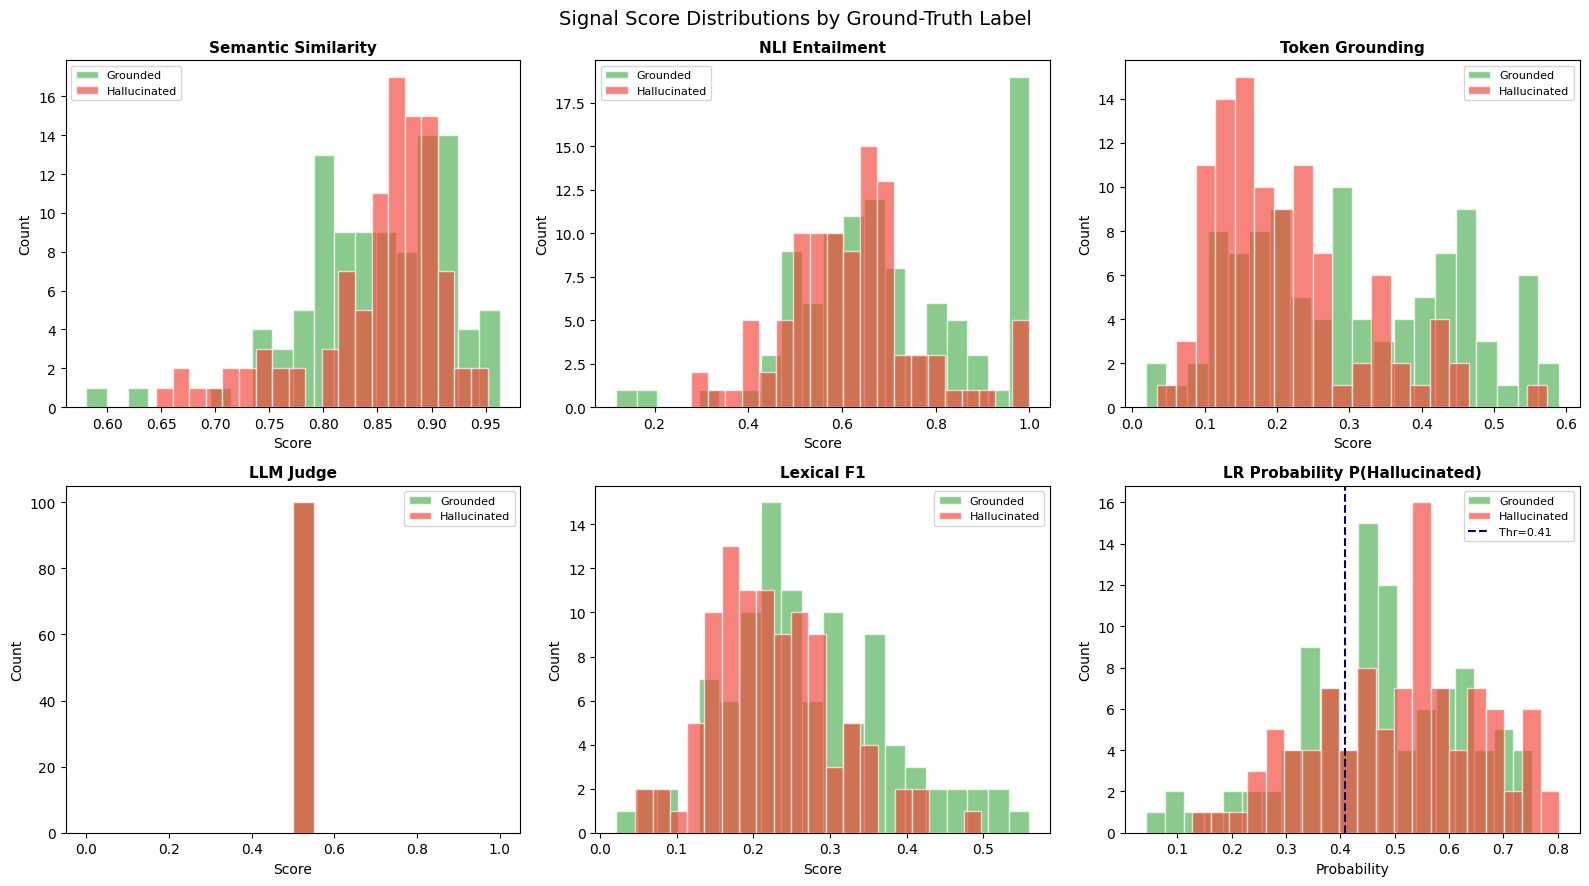

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
ax = axes.flatten()

sigs = [
    ('semantic_score',  'Semantic Similarity'),
    ('nli_score',       'NLI Entailment'),
    ('grounding_score', 'Token Grounding'),
    ('judge_score',     'LLM Judge'),
    ('lexical_score',   'Lexical F1'),
]

for i,(attr,name) in enumerate(sigs):
    h = [getattr(r.det_report, attr) for r in test_results if r.hal_label==1]
    g = [getattr(r.det_report, attr) for r in test_results if r.hal_label==0]
    ax[i].hist(g, bins=20, alpha=0.65, color='#4caf50', label='Grounded',      edgecolor='white')
    ax[i].hist(h, bins=20, alpha=0.65, color='#f44336', label='Hallucinated',  edgecolor='white')
    ax[i].set_title(name, fontsize=11, fontweight='bold')
    ax[i].legend(fontsize=8)
    ax[i].set_xlabel('Score'); ax[i].set_ylabel('Count')

# LR Probability
ph = [r.det_report.lr_prob for r in test_results if r.hal_label==1]
pg = [r.det_report.lr_prob for r in test_results if r.hal_label==0]
ax[5].hist(pg, bins=20, alpha=0.65, color='#4caf50', label='Grounded',     edgecolor='white')
ax[5].hist(ph, bins=20, alpha=0.65, color='#f44336', label='Hallucinated', edgecolor='white')
thr_g,_ = TASK_THRS.get('__global__',(0.5,0.3))
ax[5].axvline(thr_g, ls='--', color='navy', lw=1.5, label=f'Thr={thr_g:.2f}')
ax[5].set_title('LR Probability P(Hallucinated)', fontsize=11, fontweight='bold')
ax[5].legend(fontsize=8)
ax[5].set_xlabel('Probability'); ax[5].set_ylabel('Count')

plt.suptitle('Signal Score Distributions by Ground-Truth Label', fontsize=14)
plt.tight_layout(); plt.show()


## 🏁 Step 19 — Final Summary

In [ ]:
print()
print('╔' + '═'*60 + '╗')
print('║' + '  FINAL RESULTS SUMMARY'.center(60) + '║')
print('╠' + '═'*60 + '╣')
print(f'║  Dataset    : RAGTruth (QA + Summary + Data2txt)       ║')
print(f'║  Test set   : {len(test_results)} samples (balanced 50/50 hal/grnd)         ║')
print(f'║  Classifier : Task-specific LR + PR-AUC calibration    ║')
print(f'║  Corrected  : {sum(r.corrected for r in test_results):3d} samples triggered correction        ║')
print('╠' + '═'*60 + '╣')
for k,v in FINAL.items():
    bar = '█'*int(v*30)+'░'*(30-int(v*30))
    print(f'║  {k:10s}: [{bar}] {v:.4f}  ║')
print('╠' + '═'*60 + '╣')

tasks = sorted(set(r.task_type for r in test_results))
print(f'║  {"Task":<10} {"N":>4}  {"Acc":>6}  {"Prec":>6}  {"Rec":>6}  {"F1":>6}  ║')
print('║  ' + '-'*56 + '  ║')
for tt in tasks:
    sub = [r for r in test_results if r.task_type==tt]
    yt  = np.array([r.hal_label for r in sub])
    yp  = np.array([predict_lr(r)[1] for r in sub])
    a=accuracy_score(yt,yp); p_=precision_score(yt,yp,zero_division=0)
    rv=recall_score(yt,yp,zero_division=0); f=f1_score(yt,yp,zero_division=0)
    print(f'║  {tt:<10} {len(sub):>4}  {a:>6.3f}  {p_:>6.3f}  {rv:>6.3f}  {f:>6.3f}  ║')

corr_better = sum(
    r.corrected and r.corr_report and
    r.corr_report.composite_score > r.det_report.composite_score
    for r in test_results)
n_corr = sum(r.corrected for r in test_results)
print('╠' + '═'*60 + '╣')
print(f'║  Correction improvement: {corr_better}/{n_corr} corrected samples improved score  ║')
print('╚' + '═'*60 + '╝')



╔════════════════════════════════════════════════════════════╗
║                    FINAL RESULTS SUMMARY                   ║
╠════════════════════════════════════════════════════════════╣
║  Dataset    : RAGTruth (QA + Summary + Data2txt)       ║
║  Test set   : 200 samples (balanced 50/50 hal/grnd)         ║
║  Classifier : Task-specific LR + PR-AUC calibration    ║
║  Corrected  :   2 samples triggered correction        ║
╠════════════════════════════════════════════════════════════╣
║  accuracy  : [███████████████████░░░░░░░░░░░] 0.6400  ║
║  precision : [██████████████████░░░░░░░░░░░░] 0.6014  ║
║  recall    : [████████████████████████░░░░░░] 0.8300  ║
║  f1        : [████████████████████░░░░░░░░░░] 0.6975  ║
║  auc       : [█████████████████░░░░░░░░░░░░░] 0.5692  ║
╠════════════════════════════════════════════════════════════╣
║  Task          N     Acc    Prec     Rec      F1  ║
║  --------------------------------------------------------  ║
║  Data2txt     83   0.675   0.688   